# Задача 1. Семантический анализ комментариев: эмбеддинги и кластеризация

**Гипотеза (ТЗ v2):** эмбеддинги и кластеризация помогут выявлять картину негатива и боли в отзывах абонентов —
автоматически, без предварительного обучения, группировать схожие комментарии.

**Что проверяем (вопросы ТЗ):** (1) находятся ли семантически похожие комментарии в одной группе;
(2) сколько нерелевантных комментариев попадает в кластер; (3) можно ли дать кластеру понятное описание;
(4) насколько результат зависит от предобработки текста.

**Как воспроизвести** (тяжёлое — скриптами, ноутбук только читает итоги):
```
python3 research/comments/prepare_data.py        # данные + замусоривание + очистка
python3 research/comments/embed.py               # эмбеддинги (часы на CPU, кэш в build/)
python3 research/comments/experiment.py          # кластеры и метрики -> research/results/comments_metrics.csv
python3 research/comments/sensitivity.py         # настройки UMAP/HDBSCAN
python3 research/comments/describe.py --dataset bank --variant clean --model <лучшая>   # описания кластеров LLM
python3 research/make_notebooks.py               # этот ноутбук
```

In [1]:
import json, re, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "research"))
RES = ROOT / "research" / "results"
DATA = ROOT / "data" / "research"
pd.set_option("display.max_colwidth", 120, "display.width", 200)
# категориальная палитра (фиксированный порядок слотов): исходный / замусоренный / очищенный
C = {"orig": "#2a78d6", "dirty": "#eb6834", "clean": "#1baf7a"}
NAMES = {"orig": "исходный", "dirty": "замусоренный", "clean": "очищенный"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

def grouped(ax, table, variants, ylabel, title, ylim=(0, 1)):
    """Сгруппированные столбцы: модели по оси X, варианты текста — цветом (с легендой)."""
    models = list(table.index)
    w = 0.8 / len(variants)
    for j, v in enumerate(variants):
        if v not in table.columns:
            continue
        x = np.arange(len(models)) + (j - (len(variants) - 1) / 2) * w
        ax.bar(x, table[v].values, width=w * 0.92, color=C[v], label=NAMES[v], zorder=3)
    ax.set_xticks(np.arange(len(models)), models, rotation=20, ha="right")
    ax.set_ylim(*ylim); ax.set_ylabel(ylabel); ax.set_title(title, loc="left", fontsize=11)
    ax.legend(frameon=False, ncol=len(variants), loc="upper left", bbox_to_anchor=(0, -0.28))

## 1. Данные

| набор | что это | метка «о чём текст» | зачем |
|---|---|---|---|
| **bank** | 4000 отзывов о банках с banki.ru (Kaggle, датасет из ТЗ) | нет (есть рейтинг 1–5) | ближе всего к «за что ругают и хвалят»; интерпретация кластеров |
| **geo** | 4200 отзывов Яндекс Карт, 12 непохожих рубрик × 350 | рубрика | честный замер «похожие в одной группе» на открытых данных |
| **tickets** | 2984 синтетических тикета, 25 тем | скрытая тема | формат реальных тикетов: короткие, с SMM-мусором |

Варианты текста: **исходный**; **замусоренный** — по ТЗ в каждый текст ссылка, имя и телефон, а 40% текстов переписаны
в формат SMM-тикета (ссылка → переписка с шаблонными репликами оператора → блок ПД); **очищенный** — замусоренный после
очистки правилами + NER (`lurker.clean.RuleCleaner`). У тикетов исходного варианта нет: мусор в них с рождения.

In [2]:
sets = {n: pd.read_parquet(DATA / "comments" / f"{n}.parquet") for n in ("bank", "geo", "tickets")}
pd.DataFrame({n: {"текстов": len(d), "меток": d["label"].nunique() if d["label"].astype(bool).any() else 0,
                  "ср. длина исходного": round(d["orig"].str.len().mean()) if d["orig"].astype(bool).any() else None,
                  "ср. длина замусоренного": round(d["dirty"].str.len().mean()), "ср. длина очищенного": round(d["clean"].str.len().mean())}
              for n, d in sets.items()}).T

,текстов,меток,ср. длина исходного,ср. длина замусоренного,ср. длина очищенного
bank,4000.0,0.0,966.0,1157.0,952.0
geo,4200.0,12.0,285.0,472.0,278.0
tickets,2984.0,25.0,NaN,133.0,81.0


In [3]:
b = sets["bank"]
for kind in ("tz", "smm"):
    r = b[b["dirty_kind"] == kind].iloc[3]
    print(f"===== замусоривание «{kind}»\n--- замусоренный:\n{r['dirty'][:700]}\n--- очищенный:\n{r['clean'][:400]}\n")

===== замусоривание «tz»
--- замусоренный:
Здравствуйте,сегодня,07.12, обращалась в Совкомбанк с вопросом ,хочу поблагодарить сотрудника Артем Б-ый.Всё выяснили,спасибо.Жду ответ по заявлению.Всегда приятно,когда вопросы решаются быстро и квалифицированно.И вообще,в основном всегда сотрудники Совкомбанка и по горячей линии и в чате и в офисе плиогают и дают профессилнальные ответы.
https://vk.com/wall-44264986_5254?reply=1254
Новиков Андрей Владимирович
тел. +7(933)6778456
--- очищенный:
Здравствуйте,сегодня,07.12, обращалась в Совкомбанк с вопросом,хочу поблагодарить сотрудника.Всё выяснили,спасибо.Жду ответ по заявлению.Всегда приятно,когда вопросы решаются быстро и квалифицированно.И вообще,в основном всегда сотрудники Совкомбанка и по горячей линии и в чате и в офисе плиогают и дают профессилнальные ответы.

===== замусоривание «smm»
--- замусоренный:
https://yandex.ru/maps/org/603407100/reviews/
Переписка:
Мы: Добрый день! Приносим извинения за неудобства. Уточните, пожалуйста, да

## 2. Очистка: сколько мусора снимает и сколько смысла теряет
Сохранность — доля слов исходного отзыва (≥ 4 букв), оставшихся после «замусорить → очистить». Для сравнения — очистка
исходного отзыва без мусора (теряются имена сотрудников, адреса, номера — это тоже персональные данные).

In [4]:
from lurker.clean import RuleCleaner, URL_RE, PHONE_RE, EMAIL_RE
rc = RuleCleaner()
W = lambda x: set(re.findall(r"[а-яё]{4,}", x.lower()))
rows = []
for n in ("bank", "geo"):
    d = sets[n].head(1500)
    keep = [len(W(o) & W(c)) / max(len(W(o)), 1) for o, c in zip(d["orig"], d["clean"])]
    keep0 = [len(W(o) & W(rc.clean(o).text)) / max(len(W(o)), 1) for o in d["orig"]]
    rows.append({"набор": n, "сохранность после мусор→очистка": np.mean(keep), "сохранность очистки чистого текста": np.mean(keep0),
                 "ссылки в очищенном": d["clean"].str.contains(URL_RE).mean(), "телефоны в очищенном": d["clean"].str.contains(PHONE_RE).mean(),
                 "email в очищенном": d["clean"].str.contains(EMAIL_RE).mean()})
pd.DataFrame(rows).set_index("набор").round(3)

,сохранность после мусор→очистка,сохранность очистки чистого текста,ссылки в очищенном,телефоны в очищенном,email в очищенном
набор,,,,,
bank,0.982,0.983,0.0,0.0,0.0
geo,0.970,0.976,0.0,0.0,0.0


## 3. Как мусор меняет эмбеддинги — независимо от кластеризации
* **соседи сохранились** — доля общих 10 ближайших соседей текста с его исходным вариантом (1 — мусор ничего не изменил);
* **SMM видит SMM** — у текстов в SMM-формате доля соседей тоже в SMM-формате (в корпусе таких 40%: всё выше — модель
  группирует по формату, а не по смыслу);
* **в «форматных» кластерах** — доля текстов в кластерах, где ≥ 80% текстов в SMM-формате.

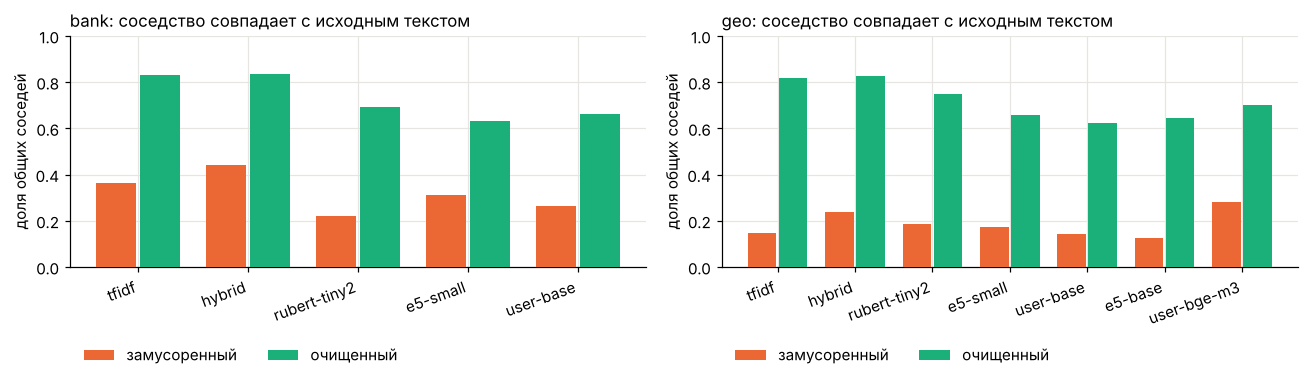

format_docs             knn_overlap        smm_nn_share              
variant                    clean  dirty orig       clean  dirty        clean  dirty   orig
dataset model                                                                             
bank    e5-small             0.0  0.000  0.0       0.630  0.313        0.385  0.786  0.391
        hybrid               0.0  0.267  0.0       0.835  0.441        0.409  0.858  0.396
        rubert-tiny2         0.0  0.211  0.0       0.694  0.220        0.422  0.945  0.404
        tfidf                0.0  0.308  0.0       0.829  0.363        0.423  0.876  0.408
        user-base            0.0  0.083  0.0       0.660  0.264        0.414  0.984  0.412
geo     e5-base              0.0  0.132  0.0       0.644  0.127        0.462  0.978  0.395
        e5-small             0.0  0.103  0.0       0.658  0.172        0.452  0.977  0.396
        hybrid               0.0  0.354  0.0       0.827  0.238        0.437  0.972  0.395
        rubert-tiny2         0.0  0.304  0.0       0.750  0.186        0.440  0.996  0.387
        tfidf                0.0  0.386  0.0       0.818  0.146        0.436  0.981  0.396
        user-base            0.0  0.166  0.0       0.623  0.141        0.488  0.997  0.409
        user-bge-m3          0.0  0.221  0.0       0.700  0.280        0.433  0.834  0.388

In [5]:
m = pd.read_csv(RES / "comments_metrics.csv")
order = [x for x in ["tfidf", "hybrid", "rubert-tiny2", "e5-small", "user-base", "e5-base", "user-bge-m3", "frida"] if x in set(m.model)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, ds in zip(axes, ("bank", "geo")):
    t = m[(m.dataset == ds) & m.variant.isin(["dirty", "clean"])].pivot(index="model", columns="variant", values="knn_overlap").reindex([o for o in order if o in set(m[m.dataset == ds].model)])
    grouped(ax, t, ["dirty", "clean"], "доля общих соседей", f"{ds}: соседство совпадает с исходным текстом")
plt.tight_layout(); plt.show()
m[m.dataset.isin(["bank", "geo"])].pivot_table(index=["dataset", "model"], columns="variant",
    values=["knn_overlap", "smm_nn_share", "format_docs"]).round(3)

## 4. Попадают ли похожие тексты в одну группу, и сколько в группе чужих
Метки: рубрика (geo), скрытая тема (tickets). **B³-точность** — для каждого текста доля «своих» в его кластере
(1 − B³-точность ≈ «доля нерелевантных в кластере»); **B³-полнота** — доля «своих», попавших в тот же кластер
(собираются ли похожие вместе; низкая — тема раздроблена на подтемы); **чистые кластеры** — доля кластеров с чистотой ≥ 0.8.
Кластеризация: UMAP (15 соседей, 5 измерений, косинус) → HDBSCAN → дораспределение выбросов (схема BERTopic с настройкой).

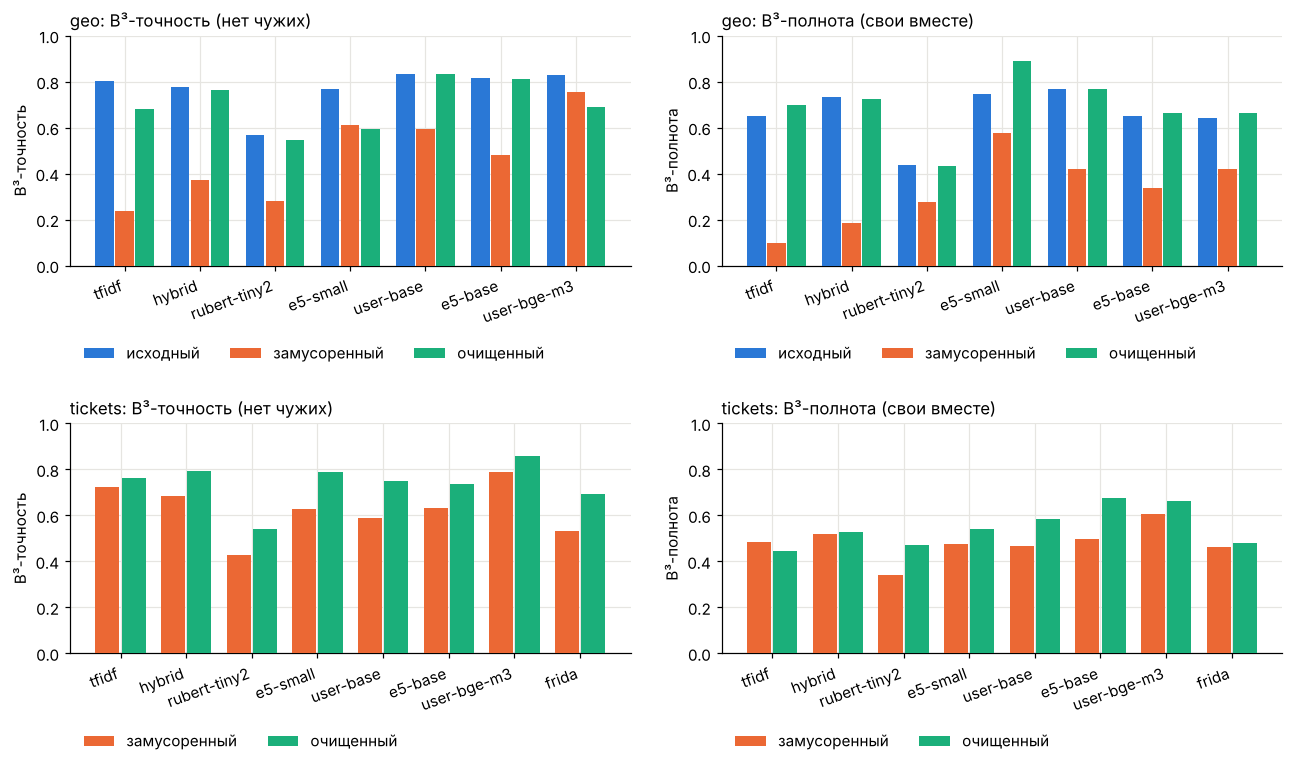

n_clusters  outliers    nmi  purity  bcubed_p  bcubed_r  clean_clusters  km_nmi  km_bcubed_p  km_bcubed_r
dataset model        variant                                                                                                           
tickets tfidf        dirty            38     0.047  0.735   0.768     0.724     0.484           0.710   0.588        0.465        0.445
                     clean            42     0.090  0.755   0.819     0.762     0.445           0.667   0.658        0.488        0.463
geo     tfidf        orig             15     0.064  0.715   0.875     0.803     0.651           0.800   0.696        0.682        0.638
                     dirty            29     0.002  0.160   0.273     0.236     0.099           0.241   0.007        0.086        0.092
                     clean            12     0.053  0.678   0.733     0.682     0.698           0.750   0.750        0.745        0.720
        hybrid       orig             14     0.003  0.747   0.871     0.775     0.732           0.857   0.712        0.710        0.681
                     dirty            27     0.000  0.297   0.434     0.372     0.185           0.370   0.062        0.130        0.120
                     clean            14     0.002  0.739   0.863     0.764     0.726           0.857   0.732        0.730        0.718
        rubert-tiny2 orig             18     0.000  0.562   0.687     0.567     0.436           0.389   0.446        0.407        0.394
                     dirty            15     0.000  0.280   0.352     0.282     0.278           0.267   0.243        0.231        0.214
                     clean            18     0.000  0.553   0.663     0.547     0.431           0.444   0.440        0.400        0.390
        e5-small     orig             13     0.000  0.779   0.848     0.766     0.748           0.769   0.671        0.640        0.618
                     dirty            17     0.000  0.623   0.678     0.614     0.576           0.412   0.563        0.522        0.500
                     clean             8     0.000  0.745   0.620     0.592     0.892           0.750   0.676        0.645        0.623
        user-base    orig             15     0.000  0.818   0.897     0.834     0.767           0.867   0.736        0.721        0.703
                     dirty            23     0.000  0.563   0.679     0.593     0.422           0.522   0.351        0.342        0.332
                     clean            15     0.000  0.821   0.895     0.834     0.768           0.867   0.735        0.699        0.695
tickets hybrid       dirty            37     0.005  0.736   0.750     0.686     0.519           0.676   0.575        0.449        0.416
                     clean            44     0.030  0.802   0.847     0.795     0.526           0.727   0.710        0.554        0.533
        rubert-tiny2 dirty            29     0.000  0.520   0.508     0.427     0.342           0.483   0.378        0.296        0.222
                     clean            33     0.000  0.642   0.624     0.540     0.472           0.576   0.550        0.429        0.375
        e5-small     dirty            34     0.000  0.690   0.708     0.627     0.474           0.559   0.532        0.425        0.344
                     clean            45     0.000  0.786   0.847     0.787     0.542           0.711   0.663        0.542        0.486
        user-base    dirty            33     0.000  0.677   0.665     0.588     0.468           0.606   0.609        0.488        0.428
                     clean            39     0.000  0.795   0.812     0.752     0.585           0.718   0.790        0.711        0.660
geo     e5-base      orig             19     0.000  0.767   0.880     0.816     0.652           0.790   0.685        0.664        0.624
                     dirty            20     0.000  0.433   0.542     0.481     0.335           0.450   0.398        0.383        0.336
                     clean            18     0.000  0.768   0.880     0.811     0.662 

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
for row, ds in enumerate(("geo", "tickets")):
    variants = ["orig", "dirty", "clean"] if ds == "geo" else ["dirty", "clean"]
    for col, metric in enumerate(("bcubed_p", "bcubed_r")):
        t = m[m.dataset == ds].pivot(index="model", columns="variant", values=metric).reindex([o for o in order if o in set(m[m.dataset == ds].model)])
        grouped(axes[row, col], t, variants, "B³-" + ("точность" if metric.endswith("p") else "полнота"),
                f"{ds}: B³-{'точность (нет чужих)' if metric.endswith('p') else 'полнота (свои вместе)'}")
plt.tight_layout(); plt.show()
cols = ["n_clusters", "outliers", "nmi", "purity", "bcubed_p", "bcubed_r", "clean_clusters", "km_nmi", "km_bcubed_p", "km_bcubed_r"]
m[m.dataset.isin(["geo", "tickets"])].set_index(["dataset", "model", "variant"])[cols].round(3)

## 5. Настройка кластеризации
Сравнение настроек UMAP/HDBSCAN с «BERTopic из коробки», HDBSCAN без UMAP, KMeans и агломеративной кластеризацией
(очищенный текст, одна модель).

In [7]:
s = pd.read_csv(RES / "sensitivity.csv") if (RES / "sensitivity.csv").exists() else pd.DataFrame()
s.set_index(["dataset", "config"])[["n_clusters", "outliers", "nmi", "bcubed_p", "bcubed_r", "purity", "clean_clusters"]].round(3) if len(s) else "нет данных"

n_clusters  outliers    nmi  bcubed_p  bcubed_r  purity  clean_clusters
dataset config                                                                                           
geo     bertopic-default                  20     0.049  0.782     0.858     0.684   0.907           0.900
        umap10-mcs10                      26     0.000  0.784     0.829     0.700   0.893           0.846
        umap10-mcs20                      17     0.000  0.807     0.831     0.743   0.895           0.882
        umap10-mcs32                      16     0.000  0.811     0.831     0.754   0.895           0.875
        umap10-mcs60                       9     0.000  0.783     0.670     0.899   0.703           0.889
        umap10-mcs100                      9     0.000  0.783     0.670     0.899   0.703           0.889
        umap15-mcs10                      24     0.000  0.789     0.832     0.679   0.895           0.875
        umap15-mcs20                      21     0.000  0.796     0.848     0.674   0.903           0.905
        umap15-mcs32                      15     0.000  0.821     0.834     0.768   0.895           0.867
        umap15-mcs60                      15     0.000  0.822     0.846     0.764   0.901           0.867
        umap15-mcs100                     10     0.000  0.820     0.742     0.888   0.780           0.900
        umap30-mcs10                      29     0.000  0.776     0.834     0.666   0.896           0.828
        umap30-mcs20                      21     0.000  0.788     0.841     0.675   0.899           0.905
        umap30-mcs32                      14     0.000  0.822     0.832     0.780   0.894           0.857
        umap30-mcs60                      14     0.000  0.825     0.833     0.780   0.894           0.857
        umap30-mcs100                     13     0.000  0.818     0.818     0.780   0.882           0.846
        umap50-mcs10                      16     0.000  0.815     0.833     0.763   0.895           0.875
        umap50-mcs20                      14     0.000  0.824     0.833     0.781   0.895           0.857
        umap50-mcs32                      14     0.000  0.822     0.832     0.780   0.894           0.857
        umap50-mcs60                      13     0.000  0.812     0.788     0.794   0.837           0.846
        umap50-mcs100                     12     0.000  0.805     0.773     0.792   0.824           0.833
        umap15-mcs32-no-reassign          15     0.026  0.812     0.854     0.755   0.907           0.867
        agglomerative-0.55                17     0.002  0.725     0.706     0.653   0.771           0.647
        hdbscan-no-umap-mcs20              3     0.752  0.122     0.826     0.083   0.351           0.667
        hdbscan-no-umap-mcs32              3     0.835  0.128     0.906     0.047   0.493           0.667
        kmeans-12                         12     0.000  0.735     0.699     0.695   0.755           0.750
        kmeans-24                         24     0.000  0.705     0.778     0.470   0.836           0.708
tickets bertopic-default                 102     0.080  0.720     0.909     0.264   0.932           0.833
        umap10-mcs10                     127     0.000  0.734     0.882     0.213   0.919           0.842
        umap10-mcs20                      68     0.000  0.767     0.826     0.393   0.872           0.824
        umap10-mcs32                      31     0.000  0.805     0.734     0.620   0.802           0.710
        umap10-mcs60                      15     0.000  0.824     0.572     0.911   0.645           0.600
        umap10-mcs100                      9     0.000  0.743     0.394     0.925   0.472           0.333
        umap15-mcs10                     124     0.000  0.740     0.888     0.238   0.921           0.831
        umap15-mcs20                      66     0.000  0.772     0.828     0.393   0.878           0.773
        umap15-mcs32                      31     0.000  0.799     0.723     0.637   0.790           0.742
      

## 6. Можно ли дать кластеру понятное описание
Для каждого значимого кластера (≥ 1% текстов): частые слова (c-TF-IDF, как в BERTopic) и описание LLM по 20 текстам
(10 ближайших к центру + 10 случайных) — локальная Qwen3-4B. «Выбивающиеся» — тексты, которые сама модель
сочла не подходящими под описание.

**6.1. Наборы с метками** (geo — рубрика места, tickets — скрытая тема): название LLM рядом с главной меткой кластера и её
долей (чистота). Ниже — проверка самооценки LLM: совпадают ли её «выбивающиеся» с реально чужими по меткам текстами.

In [8]:
for ds in ["geo", "tickets"]:
    p = RES / f"clusters_{ds}.json"
    if p.exists():
        cl = pd.DataFrame(json.loads(p.read_text(encoding="utf-8"))["clusters"])
        display(cl[["id", "size", "name", "top_label", "top_label_share", "description"]].rename(columns={"top_label_share": "чистота"}))
p = RES / "descriptions_eval.csv"
if p.exists():
    ev = pd.read_csv(p)
    g = ev.groupby("dataset").agg(кластеров=("cluster", "size"), чужих_в_выборках=("alien", "sum"), отметила_LLM=("flagged", "sum"), из_них_чужих=("hit", "sum"))
    g["точность отметок"] = (g["из_них_чужих"] / g["отметила_LLM"]).round(2)
    g["полнота отметок"] = (g["из_них_чужих"] / g["чужих_в_выборках"]).round(2)
    display(g)

,id,size,name,top_label,чистота,description
0,0,451,Пункт выдачи и обслуживание,Пункт выдачи,0.574,"Группа объединяет отзывы о пунктах выдачи, их удобстве, чистоте и качестве обслуживания персоналом. Общая тема — пол..."
1,1,385,Положительные отзывы о ресторане,Ресторан,0.862,"Группа состоит из положительных отзывов о ресторане, где пользователи выражают восхищение кухней, обслуживанием и ат..."
2,2,351,Детский сад: положительный опыт,"Детский сад, ясли",0.983,"Группа состоит из отзывов о детском саде, где родители выражают удовлетворение качеством воспитания, заботой о детях..."
3,3,349,Услуги по уходу за волосами и ногтями,Салон красоты,0.971,"Группа текстов описывает положительный опыт использования услуг маникюра, педикюра и стрижки в салоне. Клиенты отмеч..."
4,4,342,Стоматологическая клиника и лечение зубов,Стоматологическая клиника,0.965,"Группа объединяет отзывы о стоматологической клинике, где клиенты выражают положительное отношение к качеству лечени..."
5,5,342,Музей и экскурсия,Музей,0.977,"Группа объединяет тексты, посвященные музею и его экскурсиям. Общая тема — положительное восприятие музея как места ..."
6,6,342,Уютный отель с хорошим обслуживанием и разнообразным завтраком,Гостиница,0.933,"Группа состоит из отзывов о гостиницах/отелях, где клиенты выделяют высокое качество обслуживания, чистоту номеров, ..."
7,7,335,Автосервис с высоким качеством обслуживания,"Автосервис, автотехцентр",0.955,"Группа объединяет тексты, в которых клиенты оценивают качество сервиса, работу мастеров и доброжелательное отношение..."
8,8,316,Заправки и топливо,АЗС,0.984,"Группа объединяет отзывы о заправках, акцентируя внимание на качестве бензина, обслуживании, персонале и наличии коф..."
9,9,307,Аптека и её обслуживание,Аптека,0.984,"Группа объединяет тексты, описывающие опыт покупки лекарств в аптеке, качество ассортимента, обслуживания персонала ..."


,id,size,name,top_label,чистота,description
0,0,262,Подключение и тарифы,инет_смена_тарифа,0.504,"Группа объединяет тексты, связанные с вопросами подключения услуг и выбора тарифов. Общая тема — консультации по тар..."
1,1,227,Проблема с перерасчётом и списанием абонплаты,оплата_непонятная_сумма_перерасчёт,0.612,"Группа объединяет тексты, в которых клиенты жалуются на двойное списание абонплата и требуют перерасчёта. В большинс..."
2,2,195,Проблемы с интернетом,инет_обрыв_нет_связи,0.995,"Группа объединяет тексты, описывающие проблемы с пропаданием интернета, периодические сбои и предложения по подключе..."
3,3,113,Проблемы с входом в приложение,прил_вход_не_получается,0.903,"Группа объединяет тексты, связанные с проблемами входа в приложение, связанной с паролем и SMS. Клиенты сталкиваются..."
4,6,113,Проблема с приложением домофона,домофон_приложение_не_приходит_звонок,0.867,"Группа объединяет тексты, где клиенты жалуются на проблемы с функцией звонка из домофона в мобильном приложении. Осн..."
5,11,113,Проблема с опозданием мастера и приоритетом заявки,долго_ждать_мастера,0.858,"Группа объединяет тексты, в которых клиент жалуется на то, что мастер не пришёл в назначенное время. В большинстве с..."
6,4,112,Оплата и квитанции,оплата_как_оплатить_способы,0.884,"Группа объединяет тексты, в которых клиенты спрашивают способы оплаты или получают информацию о квитанциях. В больши..."
7,5,110,Заказ ключей и информация о стоимости,домофон_ключи_заказать,1.000,"Группа объединяет тексты, в которых клиенты хотят заказать ключи от домофона и спрашивают информацию о их стоимости...."
8,7,103,Проблемы с оплатой через приложение,прил_оплата_не_проходит,1.000,"Группа объединяет тексты, связанные с проблемами оплаты через приложение. Общая тема — ошибка платежа, зависший плат..."
9,8,102,Обращение с благодарностью и передачей,благодарность,1.000,"Группа объединяет тексты, в которых клиент выражает благодарность за быстрое обслуживание и передает благодарность р..."


,кластеров,чужих_в_выборках,отметила_LLM,из_них_чужих,точность отметок,полнота отметок
dataset,,,,,,
geo,14,27,22,4,0.18,0.15
tickets,25,36,65,6,0.09,0.17


**6.2. Отзывы о банках** (очищенный текст, min_cluster_size = 20; меток нет). Ниже — описания LLM и ручная проверка:
по 10 случайных текстов каждого кластера, оценка 1 / 0.5 / 0 (подходит / тема не главная / не подходит), оценка названия
и название, которое точнее отражает кластер. Проверял разработчик, а не аналитик заказчика.

In [9]:
p = RES / "clusters_bank.json"
if p.exists():
    cl = pd.DataFrame(json.loads(p.read_text(encoding="utf-8"))["clusters"])
    cols = [c for c in ["id", "size", "share", "name", "description", "sentiment", "homogeneity", "llm_outlier_share", "rating_mean", "neg_share", "keywords"] if c in cl.columns]
    display(cl[cols])
else:
    print("нет research/results/clusters_bank.json")

,id,size,share,name,description,sentiment,homogeneity,llm_outlier_share,rating_mean,neg_share,keywords
0,0,1425,0.3563,Обслуживание в банке,"Группа текстов описывает опыт клиентов с банковскими услугами, включая оформление карт, кредитов, обслуживание сотру...",позитив,высокая,0.05,4.86,0.013,"[банк, очень, карта, сотрудник, вопрос, год, кредит, быстро]"
1,2,339,0.0848,Проблемы с досрочным погашением ипотеки,"Группа объединяет тексты, связанные с проблемами досрочного погашения ипотечных кредитов. Клиенты сообщают о сложнос...",негатив,высокая,0.15,1.28,0.932,"[банк, ипотека, платеж, погашение, втб, обращение, досрочный, сумма]"
2,1,319,0.0798,Проблемы с сервисом и кэшбеком,"Группа состоит из отзывов, в которых пользователи описывают проблемы с сервисом банка Тинькофф, связанные с кэшбеком...",смешанная,высокая,0.10,3.56,0.342,"[тинькофф, банк, карта, поддержка, очень, счет, вопрос, деньга]"
3,3,296,0.0740,Проблемы с обслуживанием и техническими проблемами в банке,"Группа объединяет тексты, где клиенты жалуются на проблемы с обслуживанием банка, сложности с приложением, негативны...",негатив,высокая,0.05,1.33,0.912,"[банк, карта, деньга, сотрудник, приложение, звонить, чат, ответ]"
4,4,175,0.0437,Акция и условия использования карты,"Группа текстов объединяет отзывы клиентов о условиях акций, связанных с оформлением и использованием кредитных или д...",смешанная,высокая,0.55,1.80,0.783,"[акция, покупка, карта, условие, банк, бонус, получить, начислить]"
5,9,161,0.0403,Проблемы с получением и оформлением кредитной карты и банковских услуг,"Группа объединяет тексты, связанные с проблемами получения и оформления кредитных карт, а также с другими банковским...",смешанная,высокая,0.15,1.41,0.907,"[банк, карта, отделение, сотрудник, счет, дать, офис, паспорт]"
6,8,159,0.0398,Проблемы с кредитами и страхованием,"Группа объединяет тексты, связанные с проблемами при получении и обслуживании кредитов, а также с условиями страхова...",негатив,высокая,0.10,1.36,0.893,"[кредит, банк, сумма, страховка, сотрудник, страховой, платеж, страхование]"
7,6,152,0.0380,Проблемы с закрытием счетов и кредитов,"Группа текстов объединяет проблемы, связанные с закрытием банковских счетов, кредитов и карт. Клиенты жалуются на за...",негатив,высокая,0.05,1.34,0.914,"[счет, банк, закрытие, закрыть, отделение, карта, заявление, обращение]"
8,12,137,0.0343,Кредитные карты и условия,"Группа текстов о кредитных картах, условиях использования, процентах, льготных периодах и проблемах с банками.",смешанная,высокая,0.10,2.28,0.650,"[карта, банк, кредит, счет, процент, месяц, кредитный, год]"
9,14,128,0.0320,Проблемы с обработкой обращений и сроками,"Группа объединяет тексты, в которых клиенты жалуются на проблемы с обработкой их обращений, задержки ответов и несоо...",негатив,высокая,0.10,1.58,0.844,"[банк, обращение, ответ, сотрудник, срок, кредит, оператор, вопрос]"


In [10]:
p = RES / "manual_review_bank_scored.csv"
if p.exists():
    mr = pd.read_csv(p)
    w = (mr["relevant"] / mr["checked"] * mr["size"]).sum() / mr["size"].sum()
    print(f"Ручная проверка: {len(mr)} кластеров × 10 случайных текстов; доля подходящих под описание: "
          f"{mr['relevant'].sum() / mr['checked'].sum():.2f} (с учётом размера кластеров {w:.2f}; строго {mr['strict'].sum() / mr['checked'].sum():.2f})")
    print("Названия:", mr["name_ok"].value_counts().to_dict())
    display(mr[["cluster", "size", "name", "relevant", "checked", "name_ok", "better_name", "comment"]])

Ручная проверка: 18 кластеров × 10 случайных текстов; доля подходящих под описание: 0.80 (с учётом размера кластеров 0.85; строго 0.71)
Названия: {'частично': 8, 'да': 8, 'нет': 2}


,cluster,size,name,relevant,checked,name_ok,better_name,comment
0,0,1425,Обслуживание в банке,10.0,10,частично,Благодарности за консультацию и обслуживание,"описание верное, но слишком общее: все 10 текстов — благодарности, тональность в названии потеряна"
1,2,339,Проблемы с досрочным погашением ипотеки,4.5,10,нет,"Ипотека, сделки с недвижимостью и затяжные разбирательства (ВТБ, Сбер)","досрочное погашение — лишь 2 из 10; общее — ипотека/недвижимость и долгие разбирательства, много ВТБ"
2,1,319,Проблемы с сервисом и кэшбеком,7.5,10,частично,"Отзывы о Тинькофф: кэшбэк, поддержка, блокировки","кластер собран по бренду; половина отзывов позитивные, а описание — «проблемы»"
3,3,296,Проблемы с обслуживанием и техническими проблемами в банке,10.0,10,частично,"Разный негатив: сбои приложения, поддержка, очереди","всё подходит под широкое описание, но это «корзина» негатива без одной темы"
4,4,175,Акция и условия использования карты,8.0,10,да,"Акции, бонусы и кэшбэк не начислили",точное
5,9,161,Проблемы с получением и оформлением кредитной карты и банковских услуг,7.0,10,частично,"Оформление, выдача и активация карт","в основном дебетовые карты, не кредитные; 3 текста — про грубость/компетентность сотрудников"
6,8,159,Проблемы с кредитами и страхованием,10.0,10,да,"Кредиты: страховки, навязанные услуги, снятие залога","точное, 10 из 10"
7,6,152,Проблемы с закрытием счетов и кредитов,6.0,10,частично,"Закрытие счетов, карт и вкладов","ядро верное, 3 текста про другое (перевод, спам-звонки)"
8,12,137,Кредитные карты и условия,8.0,10,да,"Кредитные карты: льготный период, проценты, скрытые платежи",точное
9,14,128,Проблемы с обработкой обращений и сроками,9.0,10,да,Затянутые обращения и нарушенные сроки,"верное, но тема широкая и пересекается с другими"


## 7. Масштаб: 40 тысяч тикетов
Скорость моделей на 4 ядрах CPU (без GPU), замер в одиночку (`research/comments/speed.py`); оценка времени на 40 000 тикетов.
Ниже — прогон 40 000 синтетических тикетов целиком: очистка, эмбеддинги, UMAP + HDBSCAN, качество против скрытых тем.

In [11]:
sp = pd.read_csv(RES / "speed_cpu.csv").rename(columns={"reviews_per_s": "отзывов/с (~960 симв.)", "tickets_per_s": "тикетов/с (~80 симв.)",
                                                       "min_40k_tickets": "40 тыс. тикетов, мин", "load_s": "загрузка, с"})
sp.set_index("model")

,"загрузка, с",отзывов/с (~960 симв.),тикетов/с (~80 симв.),"40 тыс. тикетов, мин",cpu_threads
model,,,,,
tfidf,3.4,772.8,7478.3,0.1,4
hybrid,2.0,491.7,4760.9,0.1,4
rubert-tiny2,4.8,187.6,1316.7,0.5,4
e5-small,4.4,25.7,223.0,3.0,4
e5-base,4.4,7.9,62.5,10.7,4
user-base,1.1,5.8,64.2,10.4,4
user-bge-m3,2.0,2.4,21.9,30.4,4
frida,1.3,1.0,8.0,83.1,4


In [12]:
p = RES / "scale_40k.csv"
pd.read_csv(p).set_index("model") if p.exists() else "нет данных"

,n,clean_s,embed_s,cluster_s,n_clusters,outliers,ari,nmi,purity,bcubed_p,bcubed_r,bcubed_f,clean_clusters
model,,,,,,,,,,,,,
hybrid,39863,46,27,88,144,0.0059,0.1505,0.5907,0.7045,0.6245,0.1185,0.1993,0.4167
user-base,39863,46,547,55,119,0.0000,0.2955,0.6986,0.8421,0.7937,0.2475,0.3773,0.6807


## 8. Проверка выводов на устойчивость (аудит)
**8.1. Что именно портит эмбеддинги и обобщается ли очистка** (`research/comments/robustness.py`, отзывы Яндекс Карт):
* `dirty` — основной замусоренный вариант (60% текстов: ссылка, имя, телефон; 40% — формат SMM), `clean` — после очистки;
* `tzdirty` / `tzclean` — **только** просьба ТЗ: в каждом тексте ссылка, имя и телефон, без SMM-формата;
* `altdirty` — те же виды мусора **в форматах, под которые правила не писались** (ссылки без https, телефоны со скобками,
  «Фамилия И. О.», ники, e-mail с точкой) и 40% текстов в виде выгрузки CRM («Обращение №…», «[14:02] Пользователь:»,
  «Сотрудник поддержки (Анна):», «--- Резюме ---», «Статус: закрыто»); `altclean` — правила после исправлений аудита
  (замер правил «как было», до исправлений, — вторая таблица); `altclean_bp` — перед правилами удаление шаблонов по
  частоте в корпусе (`lurker.clean.remove_boilerplate`);
* `clean_bp` — основной вариант с удалением шаблонов (проверка, что оно не вредит).

Сохранность — доля слов исходного отзыва в очищенном; «чужие слова» — доля слов очищенного текста, которых не было в
исходном (остатки обвязки); left_* — доля текстов, где остался кусок подмешанного телефона, ссылки, e-mail, имени;
fmt_nn_share — у текстов в «особом» формате (SMM или CRM) доля соседей того же формата (в корпусе таких 40%).

In [13]:
p = RES / "robust_dirt.csv"
if p.exists():
    rd = pd.read_csv(p)
    cols = [c for c in ["nmi", "bcubed_p", "bcubed_r", "knn_overlap", "ari_vs_orig", "fmt_nn_share", "retention", "junk_share",
                        "left_phone", "left_link", "left_email", "left_name"] if c in rd.columns]
    order = ["orig", "dirty", "clean", "clean_bp", "tzdirty", "tzclean", "altdirty", "altclean", "altclean_bp"]
    rd["variant"] = pd.Categorical(rd["variant"], order)
    display(rd[rd.dataset == "geo"].sort_values(["model", "variant"]).set_index(["model", "variant"])[cols].round(3))
    display(rd[rd.dataset == "tickets"].set_index(["model", "variant"])[["nmi", "bcubed_p", "bcubed_r"]].round(3))
p = RES / "robust_dirt_before_fixes.csv"
if p.exists():
    print("Незнакомый мусор, правила и удаление шаблонов ДО исправлений аудита:")
    bf = pd.read_csv(p)
    display(bf[(bf.dataset == "geo") & bf.variant.isin(["altclean", "altclean_bp"])].set_index(["model", "variant"])
            [["nmi", "bcubed_p", "fmt_nn_share", "junk_share", "left_name", "left_phone"]].round(3))

nmi  bcubed_p  bcubed_r  knn_overlap  ari_vs_orig  fmt_nn_share  retention  junk_share  left_phone  left_link  left_email  left_name
model       variant                                                                                                                                            
e5-small    orig         0.779     0.766     0.748          NaN          NaN           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            dirty        0.623     0.614     0.576        0.172        0.560         0.977        NaN         NaN         NaN        NaN         NaN        NaN
            clean        0.745     0.592     0.892        0.658        0.521         0.452        NaN         NaN         NaN        NaN         NaN        NaN
            clean_bp     0.778     0.756     0.756        0.732        0.726         0.403        NaN         NaN         NaN        NaN         NaN        NaN
            tzdirty      0.702     0.677     0.684        0.262        0.628           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            tzclean      0.753     0.648     0.870        0.707        0.544           NaN      0.970       0.000         0.0        0.0         NaN      0.010
            altdirty     0.751     0.679     0.803        0.174        0.625         1.000        NaN         NaN         NaN        NaN         NaN        NaN
            altclean     0.676     0.747     0.377        0.269        0.470         1.000      0.977       0.269         0.0        0.0         0.0      0.053
            altclean_bp  0.735     0.719     0.695        0.406        0.683         0.916      0.977       0.066         0.0        0.0         0.0      0.053
hybrid      orig         0.747     0.775     0.732          NaN          NaN           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            dirty        0.297     0.372     0.185        0.238        0.208         0.972        NaN         NaN         NaN        NaN         NaN        NaN
            clean        0.739     0.764     0.726        0.827        0.880         0.437        NaN         NaN         NaN        NaN         NaN        NaN
            clean_bp     0.738     0.772     0.715        0.858        0.908         0.396        NaN         NaN         NaN        NaN         NaN        NaN
            tzdirty      0.496     0.548     0.360        0.364        0.389           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            tzclean      0.695     0.642     0.752        0.844        0.673           NaN      0.970       0.000         0.0        0.0         NaN      0.010
            altdirty     0.403     0.483     0.277        0.272        0.340         0.996        NaN         NaN         NaN        NaN         NaN        NaN
            altclean     0.403     0.514     0.288        0.375        0.430         0.998      0.977       0.269         0.0        0.0         0.0      0.053
            altclean_bp  0.743     0.770     0.732        0.734        0.869         0.648      0.977       0.066         0.0        0.0         0.0      0.053
tfidf       orig         0.715     0.803     0.651          NaN          NaN           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            dirty        0.160     0.236     0.099        0.146        0.069         0.981        NaN         NaN         NaN        NaN         NaN        NaN
            clean        0.678     0.682     0.698        0.818        0.641         0.436        NaN         NaN         NaN        NaN         NaN        NaN
            clean_bp     0.705     0.795     0.642        0.866        0.869         0.394        NaN         NaN         NaN        NaN         NaN        NaN
            tzdirty      0.298     0.366     0.188        0.254        0.142           NaN        NaN         NaN         NaN        NaN         NaN        NaN
            tzclean      0.

nmi  bcubed_p  bcubed_r
model       variant                            
tfidf       dirty     0.735     0.724     0.484
            clean     0.755     0.762     0.445
            clean_bp  0.776     0.815     0.464
hybrid      dirty     0.736     0.686     0.519
            clean     0.802     0.795     0.526
            clean_bp  0.811     0.824     0.537
e5-small    dirty     0.690     0.627     0.474
            clean     0.786     0.787     0.542
            clean_bp  0.811     0.810     0.569
user-base   dirty     0.677     0.588     0.468
            clean     0.795     0.752     0.585
            clean_bp  0.837     0.812     0.651
user-bge-m3 dirty     0.827     0.788     0.605
            clean     0.860     0.857     0.662
            clean_bp  0.850     0.875     0.618

Незнакомый мусор, правила и удаление шаблонов ДО исправлений аудита:


nmi  bcubed_p  fmt_nn_share  junk_share  left_name  left_phone
model     variant                                                                      
tfidf     altclean     0.378     0.548         0.999       0.287      0.417       0.167
          altclean_bp  0.557     0.677         0.900       0.147      0.414       0.132
hybrid    altclean     0.400     0.514         0.998       0.287      0.417       0.167
          altclean_bp  0.686     0.738         0.887       0.147      0.414       0.132
e5-small  altclean     0.680     0.720         1.000       0.287      0.417       0.167
          altclean_bp  0.664     0.704         0.988       0.147      0.414       0.132
user-base altclean     0.672     0.746         1.000       0.287      0.417       0.167
          altclean_bp  0.717     0.762         0.983       0.147      0.414       0.132

**8.2. Разброс от случайного зерна UMAP** (5 зёрен, те же эмбеддинги): различие моделей меньше разброса — шум.

In [14]:
p = RES / "seeds.csv"
if p.exists():
    sd = pd.read_csv(p)
    display(sd.groupby(["dataset", "variant", "model"])[["nmi", "bcubed_p", "bcubed_r", "n_clusters"]].agg(["mean", "std"]).round(3))

nmi        bcubed_p        bcubed_r        n_clusters       
                               mean    std     mean    std     mean    std       mean    std
dataset variant  model                                                                      
geo     clean    e5-base      0.756  0.013    0.776  0.069    0.666  0.044       17.4  2.510
                 e5-small     0.752  0.013    0.627  0.052    0.865  0.048        8.8  1.304
                 hybrid       0.733  0.021    0.735  0.056    0.741  0.021       13.2  1.095
                 user-base    0.819  0.002    0.833  0.001    0.766  0.006       15.2  0.447
                 user-bge-m3  0.775  0.028    0.809  0.067    0.651  0.019       20.2  1.483
        orig     e5-base      0.760  0.006    0.770  0.048    0.684  0.035       17.6  1.673
                 e5-small     0.772  0.006    0.738  0.029    0.756  0.016       12.6  1.517
                 hybrid       0.742  0.005    0.774  0.004    0.720  0.012       15.0  1.000
                 user-base    0.821  0.004    0.836  0.002    0.771  0.009       14.8  0.447
                 user-bge-m3  0.791  0.003    0.841  0.009    0.647  0.010       20.6  0.894
tickets clean    e5-base      0.814  0.008    0.753  0.024    0.637  0.029       36.6  2.074
                 e5-small     0.786  0.002    0.786  0.006    0.527  0.013       46.0  1.414
                 hybrid       0.801  0.007    0.791  0.019    0.554  0.032       42.8  2.280
                 user-base    0.803  0.008    0.764  0.018    0.600  0.010       38.2  0.837
                 user-bge-m3  0.863  0.005    0.843  0.017    0.682  0.014       38.2  1.924
        clean_bp user-base    0.839  0.004    0.829  0.018    0.630  0.023       41.8  2.490
                 user-bge-m3  0.851  0.005    0.870  0.015    0.618  0.021       43.8  1.789

**8.3. Отзывы о банках: бренды и тональность кластеров.** В данных есть название банка и рейтинг — по ним видно, что
кластеры делятся сначала по тональности (благодарности отдельно от жалоб), а часть кластеров — по бренду.

In [15]:
p = RES / "bank_clusters_brand_rating.csv"
if p.exists():
    display(pd.read_csv(p))
p = RES / "names_check.csv"
if p.exists():
    nc = pd.read_csv(p)
    print("Названия LLM против главных меток (geo, tickets):", nc.name_ok.value_counts().to_dict())
    display(nc[nc.name_ok != "да"])

,cluster,size,name,top_bank,top_bank_share,bank_share_in_corpus,rating_mean,neg_share
0,0,1425,Обслуживание в банке,Совкомбанк,0.28,0.119,4.86,0.01
1,2,339,Проблемы с досрочным погашением ипотеки,ВТБ,0.53,0.101,1.28,0.93
2,1,319,Проблемы с сервисом и кэшбеком,Тинькофф Банк,0.94,0.126,3.56,0.34
3,3,296,Проблемы с обслуживанием и техническими пробл,Сбербанк,0.13,0.058,1.33,0.91
4,4,175,Акция и условия использования карты,Альфа-Банк,0.18,0.065,1.80,0.78
5,9,161,Проблемы с получением и оформлением кредитной,ВТБ,0.32,0.101,1.41,0.91
6,8,159,Проблемы с кредитами и страхованием,ВТБ,0.14,0.101,1.36,0.89
7,6,152,Проблемы с закрытием счетов и кредитов,ВТБ,0.20,0.101,1.34,0.91
8,12,137,Кредитные карты и условия,Хоум Кредит Банк,0.18,0.082,2.28,0.65
9,14,128,Проблемы с обработкой обращений и сроками,ВТБ,0.16,0.101,1.58,0.84


Названия LLM против главных меток (geo, tickets): {'да': 38, 'частично': 1}


,dataset,cluster,name,top_label,name_ok,comment,judge
12,geo,12,Обслуживание в магазине,Пункт выдачи,частично,"смешанный кластер: пункты выдачи 45%, супермаркеты 39%; название — только про магазины",разработчик: название против главных меток кластера


## 9. Динамика: «стали ли чаще жаловаться на домофон в приложении?»
С этого вопроса началось ТЗ. В синтетические тикеты при генерации заложены события по датам: всплеск жалоб на домофон в
приложении в марте, рост ошибок оплаты с июня, плавный рост расторжений, зимний сезон низкой скорости, рост угроз и
новая тема в августе. Кластеры (очищенный текст, USER-bge-m3, без разметки) считаются по неделям, поиск изменений —
`lurker.dynamics.detect_changes` (всплеск, новая тема, рост, спад); то же для сравнения — по настоящим темам
(`research/comments/dynamics_check.py`).

In [16]:
p = RES / "dynamics_check.csv"
if p.exists():
    dc = pd.read_csv(p)
    print(f"заложенных событий найдено по кластерам: {dc['найдено по кластерам'].sum()} из {len(dc)}; "
          f"по настоящим темам: {dc['найдено по настоящим темам'].sum()} из {len(dc)}")
    display(dc.drop(columns=["находка"]))
    fd = pd.read_csv(RES / "dynamics_findings.csv")
    display(fd[fd.source == "кластеры"][["kind", "name", "topic", "period", "count", "baseline", "factor"]])

заложенных событий найдено по кластерам: 5 из 7; по настоящим темам: 4 из 7


,заложено,тема,тикетов темы,кластеров с этой темой главной,доля темы в этих кластерах,ожидаемая находка,найдено по кластерам,найдено по настоящим темам,корреляция недельных рядов
0,всплеск_март,домофон_приложение_не_открывает_дверь,69,1,0.99,spike,False,False,0.92
1,всплеск_март,домофон_приложение_не_приходит_звонок,125,2,1.00,spike,True,True,0.99
2,сезон_зима,инет_низкая_скорость_вечером,277,6,0.92,decline,True,False,0.97
3,рост_негатива_2мес,оскорбления_угрозы,49,1,1.00,spike|growth,True,True,1.00
4,рост_с_июня,прил_оплата_не_проходит,103,1,1.00,growth,True,True,1.00
5,новая_тема_август,прил_после_обновления_ошибки,23,0,0.00,new,False,True,NaN
6,рост_плавный,расторжение_дорого_конкурент,133,2,0.99,growth,True,False,1.00


,kind,name,topic,period,count,baseline,factor
0,spike,Проблема с приложением домофона,6,2026-03-09,14.0,2.0,7.00
1,spike,Проблема с интернет-скоростью в вечернее время,18,2026-01-26,7.0,1.0,7.00
2,spike,Негативные взаимодействия с операторами,19,2026-07-27,7.0,1.0,7.00
3,spike,NaN,40,2026-03-09,6.0,0.0,6.00
4,spike,Проблемы с оплатой через приложение,7,2026-07-27,11.0,2.0,5.50
5,spike,Проблема с приложением домофона,6,2026-03-23,10.0,2.0,5.00
6,growth,Негативные взаимодействия с операторами,19,NaN,29.0,6.0,4.29
7,growth,Проблема с общением в офисе,32,NaN,24.0,8.0,2.78
8,growth,Проблемы с оплатой через приложение,7,NaN,59.0,25.0,2.31
9,growth,NaN,33,NaN,17.0,7.0,2.25


корреляция недельных рядов: 0.99


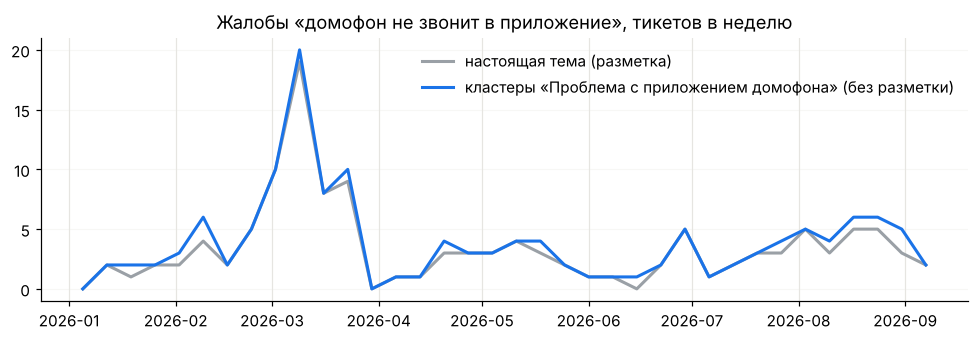

In [17]:
from lurker.dynamics import timeline
t = pd.read_parquet(ROOT / "data" / "research" / "comments" / "tickets.parquet") if (ROOT / "data" / "research" / "comments" / "tickets.parquet").exists() else None
lab = ROOT / "build" / "research" / "clusters" / "tickets__clean__user-bge-m3.npy"
if t is not None and lab.exists():
    t["date"] = pd.to_datetime(t["date"]); t["cluster"] = np.load(lab)
    topic = "домофон_приложение_не_приходит_звонок"
    cls = t[t.label == topic].cluster.value_counts().index[:2].tolist()
    weeks = timeline(t, topic_col="label", freq="W")
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(weeks.index, weeks[topic], color="#9aa0a6", lw=2, label="настоящая тема (разметка)")
    by_cl = timeline(t[t.cluster.isin(cls)].assign(g="кластеры"), topic_col="g", freq="W")["кластеры"].reindex(weeks.index, fill_value=0)
    ax.plot(weeks.index, by_cl, color="#1a73e8", lw=2, label="кластеры «Проблема с приложением домофона» (без разметки)")
    print(f"корреляция недельных рядов: {np.corrcoef(weeks[topic], by_cl)[0, 1]:.2f}")
    ax.set_title("Жалобы «домофон не звонит в приложение», тикетов в неделю"); ax.grid(axis="y", alpha=.3)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()
else:
    print("нужны data/research и build/research (запустить prepare_data.py и experiment.py)")

## 10. Какие темы появляются и какие необычные проблемы встречаются
Два вопроса заказчика из ТЗ, которые кластеры сами по себе не закрывают (`research/comments/novelty.py`).

**10.1. Новые темы по месяцам.** Для каждого месяца: эталон — все тикеты до него; тикет «новый», если его 5 ближайших
соседей в эталоне дальше, чем у 99% тикетов эталона между собой; новые тикеты группируются, группа ≥ 5, у которой и центр
далёк от прошлого, — кандидат в новую тему (`lurker.novelty.emerging_groups`). В тикеты при генерации заложена одна новая тема (с 10 августа); остальные месяцы показывают ложные тревоги.

In [18]:
p = RES / "novelty_emerging.csv"
pd.read_csv(p).drop(columns=["примеры"], errors="ignore") if p.exists() else "нет данных"

,месяц,тикетов,новизна выше порога,тикетов новых тем в месяце,из них отмечены новизной,групп-кандидатов,из них новая тема,группы
0,2026-02,344,2,0,0,0,0,NaN
1,2026-03,378,4,0,0,0,0,NaN
2,2026-04,344,4,0,0,0,0,NaN
3,2026-05,366,7,0,0,0,0,NaN
4,2026-06,314,6,0,0,0,0,NaN
5,2026-07,392,1,0,0,0,0,NaN
6,2026-08,391,14,17,9,1,1,6 шт · прил_после_обновления_ошибки 100% · НОВАЯ
7,2026-09,78,1,0,0,0,0,NaN


**10.2. Необычные комментарии.** В очищенные тикеты подмешаны 50 написанных вручную необычных, но правдоподобных
обращений («роутер искрит», «домофон сам открывает дверь ночью», «в квитанции чужая фамилия») и — контроль — 50 написанных
тем же автором ОБЫЧНЫХ. Метод из задачи 2: новизна относительно 10 ближайших соседей — внутри кластера и по всему
корпусу; варианты «от 4 слов» не ранжируют короткие тексты (опечатки, «см. предыдущий»). Если контрольные тоже всплывают,
метод ловит стиль автора, а не необычный смысл. Ниже — та же новизна на настоящих отзывах о банках, топ-20 прочитан вручную.

In [19]:
p = RES / "novelty_unusual.csv"
if p.exists():
    display(pd.read_csv(p)[["метод", "позитив", "n_pos", "доля", "ap", "auc", "p@20", "p@50", "помечено z≥2.5, %", "доля позитива среди z≥2.5"]])
    top = pd.read_csv(RES / "novelty_unusual_top.csv")
    print("Топ-40 самых необычных (по всему корпусу, тексты от 4 слов):", top["kind"].value_counts().to_dict())
    display(top.head(25))
p = RES / "novelty_bank_top20_manual.csv"
if p.exists():
    bm = pd.read_csv(p)
    print("Настоящие отзывы о банках, топ-20 самых необычных — ручная проверка:", bm["необычная проблема"].value_counts().to_dict())
    display(bm[["rank", "z", "rating", "необычная проблема", "комментарий", "text"]])

,метод,позитив,n_pos,доля,ap,auc,p@20,p@50,"помечено z≥2.5, %",доля позитива среди z≥2.5
0,knn в кластере,необычный,50,0.0165,0.524,0.992,0.40,0.60,4.8,0.340
1,knn в кластере,обычный_контроль,50,0.0165,0.052,0.705,0.10,0.12,3.4,0.067
2,центр кластера,необычный,50,0.0165,0.344,0.969,0.45,0.40,6.4,0.227
3,центр кластера,обычный_контроль,50,0.0165,0.031,0.581,0.00,0.08,5.2,0.045
4,knn без кластеров,необычный,50,0.0165,0.711,0.995,0.60,0.72,4.0,0.393
5,knn без кластеров,обычный_контроль,50,0.0165,0.055,0.720,0.15,0.12,2.7,0.098
6,"knn в кластере, от 4 слов",необычный,50,0.0165,0.639,0.995,0.70,0.66,4.3,0.385
7,"knn в кластере, от 4 слов",обычный_контроль,50,0.0165,0.064,0.717,0.20,0.14,2.9,0.080
8,"knn без кластеров, от 4 слов",необычный,50,0.0165,0.857,0.997,0.90,0.82,3.6,0.444
9,"knn без кластеров, от 4 слов",обычный_контроль,50,0.0165,0.080,0.731,0.25,0.14,2.2,0.118


Топ-40 самых необычных (по всему корпусу, тексты от 4 слов): {'необычный': 33, 'тикет': 5, 'обычный_контроль': 2}


,rank,z,kind,label,text
0,1,6.42,необычный,NaN,оператор в чате прислал абоненту фото своего кота вместо ответа
1,2,6.23,необычный,NaN,"в личном кабинете отображается договор умершего отца, переоформить не дают"
2,3,6.07,необычный,NaN,приставка вместо каналов играет радио на иностранном языке
3,4,5.75,необычный,NaN,мастер пришёл в нетрезвом виде и уснул в коридоре
4,5,5.69,необычный,NaN,роутер нагревается так что на нём плавится пластиковая полка
5,6,5.55,необычный,NaN,голосовой помощник на линии отвечает абоненту стихами
6,7,5.53,необычный,NaN,в приложении видны камеры чужого подъезда в другом районе
7,8,5.50,необычный,NaN,"кот перегрыз кабель интернета, абонент просит компенсацию за ветеринара"
8,9,5.50,необычный,NaN,"курьер привёз абоненту приставку, а в коробке кирпич"
9,10,5.32,тикет,оплата_непонятная_сумма_перерасчёт,суумма больше чем обычно


Настоящие отзывы о банках, топ-20 самых необычных — ручная проверка: {'нет': 13, 'да': 4, 'частично': 3}


,rank,z,rating,необычная проблема,комментарий,text
0,1,4.71,5,да,редкая тема: вступление в клуб амбассадоров банка,"Здравствуйте! Не могла понять, как мне вступить в клуб Амбассадоров в, мне никак не приходила ссылка на группу. Вчер..."
1,2,4.26,2,да,"опечатка в авиабилете, купленном через сервис банка","Отец брал билеты аэрофлот. Опечатка в латинском написании фамилии, т.к. в одной семье 2 написания в загранпаспортах...."
2,3,4.22,1,частично,"невнятный пересказ слухов от сотрудников, грозит забрать вклады","Трудно поверить в такое, но информация получена от сотрудников ДО на и еще двух новых девочек, одну из которых тоже ..."
3,4,4.18,5,частично,"необычный контекст (брат на СВО), сама проблема обычная — оплата ипотеки","У моего брата ипотека, он сейчас на военных действиях 13.12.3022 я решила попробовать оплатить за него ипотеку сама,..."
4,5,4.14,5,нет,обычная похвала бонусной программы,"Банк начислил бонусы согласно программе лояльности с выгодой. Никакого обмана нет, бонусы начисляются совместно с АЗ..."
5,6,4.02,1,нет,"очередь в отделении, написано с сарказмом","Газпромбанк, отделение. Очередь от 1 часа. В отделении более 10 сотрудников, реально работают 2. Остальные с трудом ..."
6,7,3.97,1,нет,очередь в отделении,Ничего не поменялось за два года после моего прошлого визита. Очереди как в советском союзе за колбасой. Сидят сотру...
7,8,3.92,5,да,консультация бухгалтера по системе налогообложения — редкая услуга,Быстро и конструктивно была помощь от бухгалтера. Рассчитала по кварталам - доходы и расходы. Предложила варианты вы...
8,9,3.75,1,нет,навязанный пакет услуг — частая тема,Зачем нужно это приложение если для того что бы закрыть не нужный пакет услуг машиностроитель нужно ехать в офис или...
9,10,3.64,1,нет,навязанная сумма при рефинансировании — частая тема,Почему при оформлении рефинансирования ВПИХИВАЕТСЯ ненужная мне дополнительная сумма не менее чем на 30000руб? Это -...


## 11. Что положительного или отрицательного пишут: тональность без оценок
Готовые открытые модели тональности, без обучения (`research/comments/sentiment.py`). Проверка: отзывы о банках и
Яндекс Картах — по рейтингу (1–2 негатив, 3 нейтрально, 4–5 позитив), тикеты — по скрытой разметке генератора.
Тикеты — заметки оператора о клиенте, а не отзывы, поэтому для них проверка отдельная. Ниже — доля негатива по
кластерам: предсказанная моделью против настоящей.

In [20]:
p = RES / "sentiment_eval.csv"
if p.exists():
    display(pd.read_csv(p).pivot_table(index="model", columns="dataset", values=["macro_f1", "auc_neg"]).round(3))
    display(pd.read_csv(p))
for ds in ("tickets", "bank"):
    p = RES / f"sentiment_clusters_{ds}.csv"
    if p.exists():
        ct = pd.read_csv(p)
        big = ct[ct["size"] >= 30]
        print(f"{ds}: доля негатива по кластерам — корреляция с настоящей {np.corrcoef(big.negative_true, big.negative_pred)[0, 1]:.2f}, "
              f"средняя ошибка {100 * (big.negative_true - big.negative_pred).abs().mean():.0f} п.п.")
        display(ct.head(20))

auc_neg                macro_f1               
dataset                                        bank    geo tickets     bank    geo tickets
model                                                                                     
blanchefort/rubert-base-cased-sentiment       0.863  0.932   0.633    0.596  0.577   0.473
cointegrated/rubert-tiny-sentiment-balanced   0.813  0.932   0.679    0.474  0.547   0.570
seara/rubert-base-cased-russian-sentiment     0.928  0.976   0.799    0.549  0.641   0.489
seara/rubert-tiny2-russian-sentiment          0.921  0.966   0.790    0.528  0.606   0.505

,dataset,model,n,macro_f1,f1_neg,f1_pos,auc_neg,neg_share_true,neg_share_pred,texts_per_s
0,tickets,seara/rubert-tiny2-russian-sentiment,2984,0.505,0.388,0.676,0.790,0.716,0.187,228.9
1,tickets,seara/rubert-base-cased-russian-sentiment,2984,0.489,0.315,0.711,0.799,0.716,0.147,14.1
2,tickets,blanchefort/rubert-base-cased-sentiment,2984,0.473,0.526,0.443,0.633,0.716,0.322,49.8
3,tickets,cointegrated/rubert-tiny-sentiment-balanced,2984,0.570,0.739,0.510,0.679,0.716,0.603,323.7
4,geo,seara/rubert-tiny2-russian-sentiment,4195,0.606,0.677,0.912,0.966,0.094,0.069,440.9
5,geo,seara/rubert-base-cased-russian-sentiment,4195,0.641,0.724,0.927,0.976,0.094,0.072,25.8
6,geo,blanchefort/rubert-base-cased-sentiment,4195,0.577,0.675,0.935,0.932,0.094,0.120,28.6
7,geo,cointegrated/rubert-tiny-sentiment-balanced,4195,0.547,0.599,0.886,0.932,0.094,0.120,292.1
8,bank,seara/rubert-tiny2-russian-sentiment,4000,0.528,0.698,0.779,0.921,0.519,0.329,138.7
9,bank,seara/rubert-base-cased-russian-sentiment,4000,0.549,0.799,0.753,0.928,0.519,0.429,8.0


tickets: доля негатива по кластерам — корреляция с настоящей 0.51, средняя ошибка 49 п.п.


,cluster,name,size,negative_true,negative_pred,positive_true,positive_pred
0,0,Подключение и тарифы,262,0.008,0.229,0.0,0.107
1,1,Проблема с перерасчётом и списанием абонплаты,227,0.991,0.348,0.0,0.167
2,2,Проблемы с интернетом,195,1.000,0.236,0.0,0.082
3,3,Проблемы с входом в приложение,113,1.000,0.398,0.0,0.009
4,6,Проблема с приложением домофона,113,1.000,0.451,0.0,0.027
5,11,Проблема с опозданием мастера и приоритетом заявки,113,1.000,0.673,0.0,0.018
6,4,Оплата и квитанции,112,0.000,0.259,0.0,0.018
7,5,Заказ ключей и информация о стоимости,110,0.000,0.155,0.0,0.091
8,7,Проблемы с оплатой через приложение,103,1.000,0.291,0.0,0.000
9,8,Обращение с благодарностью и передачей,102,0.000,0.078,1.0,0.794


bank: доля негатива по кластерам — корреляция с настоящей 0.99, средняя ошибка 4 п.п.


,cluster,name,size,negative_true,negative_pred,positive_true,positive_pred
0,0,Обслуживание в банке,1425,0.013,0.128,0.981,0.785
1,2,Проблемы с досрочным погашением ипотеки,339,0.932,0.923,0.029,0.003
2,1,Проблемы с сервисом и кэшбеком,319,0.342,0.476,0.627,0.451
3,3,Проблемы с обслуживанием и техническими проблемами в банке,296,0.912,0.912,0.027,0.024
4,4,Акция и условия использования карты,175,0.783,0.811,0.166,0.063
5,9,Проблемы с получением и оформлением кредитной карты и банковских услуг,161,0.907,0.944,0.050,0.012
6,8,Проблемы с кредитами и страхованием,159,0.893,0.937,0.044,0.006
7,6,Проблемы с закрытием счетов и кредитов,152,0.914,0.921,0.046,0.007
8,12,Кредитные карты и условия,137,0.650,0.745,0.277,0.102
9,14,Проблемы с обработкой обращений и сроками,128,0.844,0.789,0.094,0.031


## 12. Отзывы о банках: кластеры по брендам и «мешок» благодарностей
`research/comments/bank_brands.py`: (1) названия банков и их продуктов в тексте заменены словом «банк» — меньше ли
кластеров «по бренду»; (2) крупные кластеры (> 15% корпуса) кластеризованы второй раз внутри себя — подтемы.

In [21]:
for f in ("bank_brands.csv", "bank_subclusters.csv"):
    p = RES / f
    if p.exists():
        display(pd.read_csv(p))

,вариант,кластеров,"крупнейший, доля",NMI с банком,кластеров ≥ 90% одного банка,NMI с тональностью (рейтинг)
0,очищенный текст,20,0.356,0.295,4,0.297
1,без названий банков,2,0.598,0.125,0,0.662
2,очищенный текст + вторая ступень,27,0.085,0.366,6,0.246
3,без названий банков + вторая ступень,15,0.104,0.207,0,0.296


,вариант,кластер,размер кластера,подкластер,размер,средний рейтинг,ключевые слова,пример
0,очищенный текст,0,1425,1,311,4.98,"банк, сотрудник, очень, вопрос, отделение, кредит","Спасибо большое за помощь работнику отделения ДО обращалась 24.12.2022 г., так как неделю ждала обращалась онлайн и ..."
1,очищенный текст,0,1425,0,260,4.80,"банк, совкомбанк, карта, халва, очень, сотрудник","Здравствуйте,сегодня,07.12, обращалась в Совкомбанк с вопросом,хочу поблагодарить сотрудника.Всё выяснили,спасибо.Жд..."
2,очищенный текст,0,1425,2,178,4.99,"россельхозбанк, сотрудник, банк, офис, очень, рассказать",В 2022 года открыл для себя Россельхозбанк и не пожалел. В январе первый раз обратился за обслуживанием в Дополнител...
3,очищенный текст,0,1425,4,177,4.78,"банк, вопрос, карта, сотрудник, чат, деньга",Всем Добрый День и С Наступающим Новым Годом. с 2007 г являюсь клиентом банка Русский Стандарт Случилось так что ока...
4,очищенный текст,0,1425,3,168,4.51,"карта, банк, пользоваться, месяц, счет, покупка",В наше время такое редко бывает. Но я нахожусь во взаимодействии с банком Хоум Кредит с 2010 года. Когда были деньги...
5,очищенный текст,0,1425,6,124,4.91,"банк, очень, вопрос, быстро, приложение, вклад","Ольга Наша организация работает с примерно 2 года. За это время у нас ни разу не возникало вопросов по обслуживанию,..."
6,очищенный текст,0,1425,5,123,4.92,"банк, ип, счет, год, удобный, очень",В банке Точка расчетный счет открыт больше трех лет. На сегодняшний день это лучшее мобильное приложение для малого ...
7,очищенный текст,0,1425,7,84,4.95,"карта, банк, очень, дебетовый, быстро, оформить","Данным банком пользуюсь сравнительно недавно, около полугода. это время могу сделать следующие выводы дебетовая карт..."
8,без названий банков,0,2391,3,371,1.41,"банк, деньга, перевод, карта, счет, средство","Выдали карту мужу в военкомате г., и в этот же день забрали 11 октября, карта до сих пор не активированна, не возмож..."
9,без названий банков,0,2391,2,305,1.38,"карта, банк, курьер, отделение, доставка, сотрудник",Увидел интересное предложение. Решил побаловать себя к празднику. Карта с гроссом 180 дней. Звучит отлично! Заявку о...


## 13. 40 тысяч тикетов: настройки под объём
Рекомендованный конвейер целиком (удаление шаблонов → очистка → USER-bge-m3) на 40 000 синтетических тикетов и сетка
настроек: min_cluster_size и слияние близких кластеров по центроидам (`research/comments/scale_settings.py`).

In [22]:
p = RES / "scale_40k_settings.csv"
pd.read_csv(p)[["min_cluster_size", "merge_threshold", "n_clusters", "nmi", "bcubed_p", "bcubed_r", "purity", "clean_clusters",
                "clean_s", "embed_s", "cluster_s"]] if p.exists() else "нет данных"

,min_cluster_size,merge_threshold,n_clusters,nmi,bcubed_p,bcubed_r,purity,clean_clusters,clean_s,embed_s,cluster_s
0,100,NaN,134,0.6995,0.8282,0.2026,0.8818,0.7388,111,3110,100
1,100,0.90,111,0.7075,0.8098,0.2337,0.8721,0.7477,111,3110,100
2,100,0.85,74,0.7386,0.7916,0.3819,0.8663,0.7703,111,3110,100
3,100,0.80,40,0.7673,0.7254,0.6052,0.8159,0.7750,111,3110,100
4,200,NaN,68,0.7205,0.7498,0.3315,0.8290,0.6471,111,3110,65
5,200,0.90,60,0.7261,0.7392,0.3767,0.8290,0.6833,111,3110,65
6,200,0.85,38,0.7402,0.6917,0.5431,0.7965,0.6579,111,3110,65
7,200,0.80,20,0.7135,0.4998,0.7041,0.6033,0.5500,111,3110,65
8,400,NaN,26,0.6691,0.5354,0.5026,0.6529,0.3846,111,3110,64
9,400,0.90,22,0.6724,0.5244,0.5589,0.6471,0.3636,111,3110,64


## Выводы по задаче 1

**Гипотеза подтверждается — при трёх условиях:** (1) из текста убраны мусор и служебная обвязка, причём очистку нужно
проверить и донастроить на реальной выгрузке; (2) кластеризация настроена, а не «из коробки»; (3) модель подобрана под
длину текстов. Тогда эмбеддинги + UMAP + HDBSCAN без всякого обучения собирают похожие комментарии в группы, чужих в
группах около шестой части, группам можно дать понятное описание, а на отзывах о банках получается «карта боли».
Без очистки результат разваливается ровно так, как предполагалось в ТЗ. Все различия моделей ниже проверены на разбросе
от случайного зерна (5 зёрен): разница меньше разброса за вывод не выдаётся.

**1. Находятся ли похожие комментарии в одной группе.** Да. На отзывах Яндекс Карт (12 рубрик) лучшая модель —
**USER-base** (deepvk, 124M, русская): NMI 0.82 ± 0.004, B³-полнота 0.77 — в среднем 77% «своих» (той же рубрики)
оказываются в том же кластере. На синтетических тикетах (25 тем, короткие тексты) лучше всех **USER-bge-m3**:
NMI 0.86 ± 0.005; у USER-base, e5-base и гибрида TF-IDF + navec там 0.80–0.81 — между собой они неразличимы.
Кластеров чуть больше, чем меток (15 на 12 рубрик): отзывы о банках разошлись на позитивные и негативные, «Пятёрочка»
выделилась из супермаркетов; два кластера смешанные — «вежливый персонал» пунктов выдачи и банков, жалобы на заказы в
магазинах и пунктах выдачи. Это группировка по аспекту и тону — осмысленная, но снижает формальную чистоту.

**2. Сколько нерелевантных в кластере.** Около шестой части при правильной модели: B³-точность USER-base на отзывах 0.83
(17% соседей по кластеру — из другой рубрики), 87% кластеров чистые (≥ 80% одной рубрики); USER-bge-m3 на тикетах — 0.84
(16%; с удалением шаблонов — 13%), 90% чистых. С «не той» моделью на тикетах чужих больше: у USER-base 24% (17% с
удалением шаблонов). На отзывах о банках меток нет — ручная
проверка 180 случайных текстов: **80% подходят под описание кластера** (85% с учётом размера кластеров). Доля чужих —
это ещё и ручка: крупные кластеры полнее, но грязнее (на тикетах min_cluster_size 20 → 17% чужих, но темы раздроблены;
60 → 34% чужих, зато темы целые), см. п. 5.

**3. Можно ли дать кластеру понятное описание.** Да, с проверкой глазами. Локальная Qwen3-4B (бесплатно, на CPU, ~40 с
на кластер) по 20 текстам (10 ближайших к центру + 10 случайных) дала название и описание 57 кластерам трёх наборов.
* **Где есть метки** (Яндекс Карты, тикеты): 38 из 39 названий соответствуют главной метке кластера, одно — частично
  («Обслуживание в магазине» для смеси пунктов выдачи и супермаркетов). Один сбой формата (у отелей модель вернула
  слова из шаблона «О чём группа») — теперь такой ответ переспрашивается.
* **Отзывы о банках без меток — ручная проверка** (читал разработчик, по 10 случайных текстов на кластер): названия 8 из 18
  точные, 8 частично, 2 неудачные. Типичные промахи: (а) название уже настоящей темы — модель опирается на ближайшие к
  центру тексты («досрочное погашение ипотеки» при общей теме «ипотека и сделки с недвижимостью»); (б) слишком общее
  название большого кластера («Обслуживание в банке», 1425 отзывов, а по сути это благодарности); (в) кластер собран по
  бренду, а модель выдаёт его за тему: 4 кластера из 18 на 90–100% состоят из отзывов об одном банке (Тинькофф,
  Альфа-Банк, МТС Банк, Газпромбанк), ещё в двух один банк даёт половину (ВТБ, Озон Банк).
* **Картина боли видна.** Кластеры делятся сначала по тональности: один большой кластер — благодарности (36% отзывов,
  средний рейтинг 4.9), остальные 17 — жалобы с ясными темами (доставка карты, страховки в кредитах, закрытие счетов,
  зависшие переводы, акции и кэшбэк…; у 16 из них доля негатива 65–100%, отзывы о Тинькофф — смешанные).
* **Самооценке LLM верить нельзя.** «Однородность» у всех 57 кластеров «высокая»; «выбивающиеся» тексты модель отмечает
  почти только в случайной половине выборки (там чужих и правда больше), но и там её отметки попадают в чужие по меткам
  тексты в 11–18% случаев при доле чужих 8–14% — почти наугад. Долю нерелевантных нужно мерить выборочным чтением.

**4. Насколько результат зависит от предобработки — главный вывод.** Сильно, и в обе стороны. USER-base, отзывы
Яндекс Карт, NMI с рубриками (исходный текст — 0.82):

| вариант | NMI |
|---|---|
| только просьба ТЗ: ссылка, имя и телефон в каждом тексте | 0.66 |
| + 40% текстов в формате SMM (переписка, шаблонные ответы, ПД) | 0.56 |
| после очистки правилами + NER (любой из двух) | 0.81–0.82 |
| мусор в форматах, под которые правила не писались (CRM-выгрузка и др.) | 0.67 |
| … очистка правилами как было | 0.67 |
| … правила после исправлений аудита (остатки ПД почти исчезли, обвязка осталась) | 0.66 |
| … + удаление шаблонов по частоте в корпусе | **0.78** |

* Опасение ТЗ подтвердилось даже для минимального мусора: одна ссылка, имя и телефон меняют 80% ближайших соседей текста
  (у TF-IDF NMI 0.72 → 0.30). SMM-формат добавляет группировку **по формату, а не по смыслу**: у SMM-текстов 83–100%
  ближайших соседей — тоже SMM-тексты при их доле 40% в корпусе.
* Очистка правилами и NER (`lurker.clean`) на «своём» мусоре возвращает качество полностью (USER-base 0.82 → 0.56 → 0.82,
  кластеры почти те же, ARI 0.93), сохраняет 97% слов и не оставляет ссылок и телефонов. Цена — NER вырезает из текста
  и топонимы, и имена знаменитых людей («Малаховка», «Шагал»).
* **Но правила знают только те форматы, под которые написаны.** На незнакомой выгрузке они почти не помогли: служебные
  строки «Обращение №…», «Сотрудник поддержки (Анна):», «Статус: закрыто» остались, и тексты из выгрузки по-прежнему
  соседствуют только друг с другом. Аудит нашёл и исправил ошибки правил (e-mail с точкой в имени обрезался до
  «ivan.petrov@», телефон без кода страны, ники, имя и фамилия строчными) и добавил не зависящее от формата **удаление
  шаблонов**: фразы, служебные метки и короткие строки, повторяющиеся во многих документах корпуса, вырезаются
  (`lurker.clean.remove_boilerplate`; в исходных отзывах оно не удаляет ничего). Исправленные правила убирают остатки ПД
  (имена — с 42% текстов до 5%, телефоны — с 17% до 0%), но качество возвращает именно удаление шаблонов: на незнакомой
  выгрузке USER-base — до 0.78 из 0.82, гибрид TF-IDF + navec — полностью (0.74 при 0.75 на исходном тексте). Остаток —
  метки вроде «Пользователь:», по которым тексты выгрузки всё ещё чаще соседствуют друг с другом (91% при доле 40%).
  На основном замусоренном варианте удаление шаблонов не вредит (0.82), а на тикетах, где много шаблонных фраз
  операторов, заметно помогает (5 зёрен): USER-base 0.80 → 0.84, чужих в кластере 24% → 17%; у USER-bge-m3 чужих
  16% → 13%, чистых кластеров 88% → 91% (NMI 0.86 → 0.85 — кластеры чуть мельче).
* **Практический вывод для реальных данных:** перед кластеризацией взять 50–100 тикетов каждого отдела, посмотреть
  очищенный текст и проверить простой признак: доля соседей «того же формата» (того же отдела, канала) не должна быть
  заметно выше доли этого формата в корпусе — иначе кластеры будут по отделам, а не по смыслу.

**5. Настройка кластеризации (ответ на опыт MVP заказчика).** С параметрами BERTopic по умолчанию (UMAP 15/5, HDBSCAN
min_cluster_size = 10, без дораспределения выбросов — тот же конвейер, что в BERTopic 0.17) на коротких тикетах 25 тем
дробятся на 102 кластера (B³-полнота 0.26), 8% текстов уходят в «выбросы» — отсюда «кластеры как набор шума»; на длинных
отзывах те же параметры работают прилично (NMI 0.78 против 0.82 у настроенных). HDBSCAN прямо по эмбеддингам без UMAP
проваливается (NMI 0.12, 75–83% выбросов). KMeans и агломеративная кластеризация даже с известным числом тем хуже
(NMI 0.73–0.79). Работает: UMAP (15–30 соседей, 5 измерений, косинус) → HDBSCAN (min_cluster_size ≈ √n/2 — отправная
точка; дальше это ручка «детальнее и чище» ↔ «крупнее и полнее») → выбросы к ближайшему кластеру. Длинные многотемные
отзывы (banki.ru, ~960 символов) HDBSCAN склонен склеивать в один большой кластер — короткие тикеты кластеризуются чище.

**6. Модели и масштаб.** Модель — по длине текста: короткие тикеты — **USER-bge-m3** (NMI 0.86; 40 тыс. тикетов —
30–50 мин на 4 ядрах CPU: 30 по замеру скорости в одиночку, 52 в прогоне ниже, где процессор был частично занят),
длинные отзывы — **USER-base** (0.82; на тикетах 0.80, зато втрое быстрее, 40 тыс. ≈ 10 мин).
Гибрид TF-IDF + navec — сильная и почти мгновенная база (0.74 на отзывах, 0.80 на тикетах). rubert-tiny2 заметно хуже
(0.56 на отзывах), multilingual-e5-small и e5-base — посередине; FRIDA на тикетах хуже USER-bge-m3 (0.75) и ещё в 2.7 раза
медленнее. **40 000 тикетов целиком на CPU** (`scale_settings.py`, рекомендованный конвейер с USER-bge-m3):
удаление шаблонов и очистка 2 мин, эмбеддинги 52 мин (процессор был частично занят), UMAP + HDBSCAN 1.5 мин. С min_cluster_size ≈ √n/2 темы дробятся
на осколки — 134 кластера на 25 скрытых тем (чистота 0.88, но B³-полнота 0.20). Поднимать min_cluster_size плохо
(400 → 26 кластеров, но разные темы склеиваются: чистота 0.65). Работает **слияние близких кластеров** по центрам
(сходство ≥ 0.80): 40 кластеров, NMI 0.70 → 0.77, B³-полнота 0.20 → 0.61 при чистоте 0.82 (`run_comments.py --merge 0.8`).
На 3 тыс. то же слияние вредит (18 кластеров на 25 тем, чистота 0.64) — это настройка под объём, а не умолчание.

**7. Динамика — вопрос, с которого началось ТЗ («стали ли чаще жаловаться на домофон в приложении?»).** Кластеры
можно считать по неделям и искать всплески, новые темы и рост (`lurker.dynamics`; в `run_comments.py` — таблица
`dynamics.csv`). Проверено на событиях, заложенных в синтетические тикеты при генерации: по кластерам без всякой
разметки найдено **5 из 7** — мартовский всплеск жалоб «домофон не звонит в приложение» (×7 за неделю), рост ошибок
оплаты с июня, рост угроз, плавный рост расторжений, зимний сезон низкой скорости; тот же поиск по настоящим темам
находит 4 из 7. Недельные ряды кластеров повторяют настоящие ряды тем (корреляция 0.92–1.0). Пропущены слабый всплеск
(×2 — его не видно и по настоящим темам) и **новая маленькая тема** (23 тикета за месяц): своего кластера она не
получила и растворилась в соседнем — её ловит отдельный поиск новизны (п. 8). Из 15 изменений, найденных по кластерам,
11 — заложенные события, 4 — похоже на случайные колебания.

**8. Какие темы появляются и какие необычные проблемы встречаются** (`research/comments/novelty.py`).
* **Новые темы:** для каждого месяца тикеты сравниваются со всеми тикетами до него; «новые» (дальше от прошлого, чем
  99% прошлых тикетов друг от друга) группируются, группа ≥ 5 — кандидат в новую тему. Заложенная новая тема найдена в
  первый же месяц — единственным кандидатом (6 тикетов, все из этой темы), а в остальных шести месяцах ложных «новых
  тем» нет ни одной. То, что кластеры пропускают, ловится этим отдельным поиском.
* **Необычные проблемы:** в тикеты подмешаны 50 написанных вручную необычных, но правдоподобных обращений («роутер
  искрит», «домофон сам открывает дверь ночью», «в квитанции чужая фамилия») и 50 обычных, написанных тем же автором,
  для контроля. Новизна относительно 10 ближайших соседей (метод задачи 2) без коротких текстов (< 4 слов: опечатки,
  «см. предыдущий») находит их с AP 0.86: в топ-40 — 33 необычных из 50 и только 2 контрольных, то есть ловится смысл,
  а не стиль автора. Здесь, в отличие от звонков, сравнение со всем корпусом лучше, чем внутри кластера (AP 0.86 против
  0.64): необычная проблема чужая для всех тем сразу. Оговорка: синтетические тикеты шаблонные, необычное в них заметнее,
  чем будет в жизни. На **настоящих** отзывах о банках из 20 самых «необычных» действительно необычных ситуаций 4
  (сирена банкомата при снятии своих денег, опечатка в авиабилете, купленном через банк, …), ещё 3 — частично; остальное —
  обычные темы, написанные необычно (сарказм, много деталей). То есть это рабочий «список на прочтение», а не фильтр.

**9. Что положительного или отрицательного пишут** (`research/comments/sentiment.py`). Тональность каждого комментария
готовой открытой моделью, без обучения (четыре русские модели).
* **На словах клиентов — работает.** Отзывы Яндекс Карт и о банках: негатив отделяется с AUC 0.86–0.98; доля негатива
  по кластерам у `blanchefort/rubert-base-cased-sentiment` повторяет настоящую (по рейтингу) с корреляцией 0.99 и средней
  ошибкой 4 п.п. — это готовая «карта боли»: какие темы ругают, какие хвалят.
* **На заметках операторов — не работает.** В тикетах («абонент недоволен, угрожает судом…») модели, обученные на отзывах,
  видят 15–60% негатива при настоящих 72%; по кластерам корреляция ≤ 0.51. Для тикетов тональность кластера лучше брать
  у LLM из описания: на тикетах все 13 кластеров, названных ею «негатив», и правда негативные, 4 «нейтральных» — без
  негатива, «позитив» — благодарности; ошибается она только в осторожную сторону («смешанная» у 6 полностью негативных
  кластеров). Если нужна тональность каждого тикета — дообучить маленький классификатор на нескольких сотнях размеченных
  тикетов. В `run_comments.py` — опция `--sentiment` (доли негатива и позитива по кластерам).

**10. Отзывы о банках: бренды и «мешок» благодарностей** (`research/comments/bank_brands.py`). Если удалить из текста
названия банков и их продуктов (54 шаблона, 4424 упоминания в 2127 отзывах из 4000), кластеры «по бренду» исчезают (0 из 15
против 4 из 20 на исходном тексте и 6 из 27 на исходном со второй ступенью; связь кластеров с банком NMI 0.30 → 0.21), а первая ступень делит корпус на две части — благодарности и
жалобы: тон — главная ось отзывов. Вторая ступень (крупный кластер > 15% кластеризуется ещё раз внутри себя) даёт
понятную карту: жалобы — переводы и зависшие деньги, доставка карты, сотрудники и приложение, досрочное погашение
ипотеки, акции и бонусы, комиссии, закрытие счетов, кредиты со страховками; благодарности — консультации в офисе и
вклады, карта и приложение, кредиты, счета для бизнеса, ипотека. Крупнейший кластер — 10% вместо 36%. В `run_comments.py`
вторая ступень включена по умолчанию (`--split-large 0.15`), удаление названий — опция `--mask` (пример списка —
`configs/mask_banks.txt`; для тикетов заказчика это могут быть названия продуктов, партнёров, конкурентов).

**Рекомендованный пайплайн** (`research/run_comments.py`): удаление шаблонов → очистка правилами + NER → (по желанию)
удаление названий брендов → USER-bge-m3 (короткие тексты) или USER-base (длинные) → UMAP (15, 5, cosine) → HDBSCAN
(min_cluster_size ≈ √n/2) → дораспределение выбросов → вторая ступень для кластеров > 15% → c-TF-IDF ключевые слова +
описание LLM по 20 текстам → (по желанию) тональность → динамика по месяцам → проверка названий и листа
`manual_check.csv` глазами. Новые темы и необычные комментарии — отдельный поиск новизны (`research/comments/novelty.py`).

**Ограничения.** Открытые отзывы — не тикеты заказчика; тикеты — наша синтетика; «мусор», SMM- и CRM-форматы — наша
имитация. Метки качества — рубрика места или скрытая тема, а не «боль» клиента; отзывы о банках проверены вручную, но
проверял разработчик, а не аналитик заказчика. Если в тикете есть саммари сотрудника, очистка берёт его вместо слов клиента —
на реальных SMM-тикетах стоит сравнить, что кластеризуется лучше. Отзывы о телефонах из ТЗ не использовались: в них нет
меток темы, и по смыслу они дублируют отзывы о банках.